In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
rng = np.random.default_rng(42)
#42 is nothing just a dummy seed value and is termed as a programming joke among devs



In [3]:
print(rng)

Generator(PCG64)


In [4]:
print(type(rng))

<class 'numpy.random._generator.Generator'>


In [12]:
mu,sigma,n = 0.0,1.0,1000

X = rng.normal(mu,sigma,size = (n,2))
# making the distribution with mean = mu, sd = sigma and 1000 is the size and we are making the distribution in the form of 2 D array of 1000 x 2 dimension

In [18]:

y = (X[: ,0] > np.sin(2 * X[:,1])).astype(int)
# as X is 1000 x 2 so 1 till end will fetch only the 2nd column
type(y[1])

numpy.int64

**we are choosing this method to define y because we need to have the model learn a non-linear decision boundary rather than a linear one**
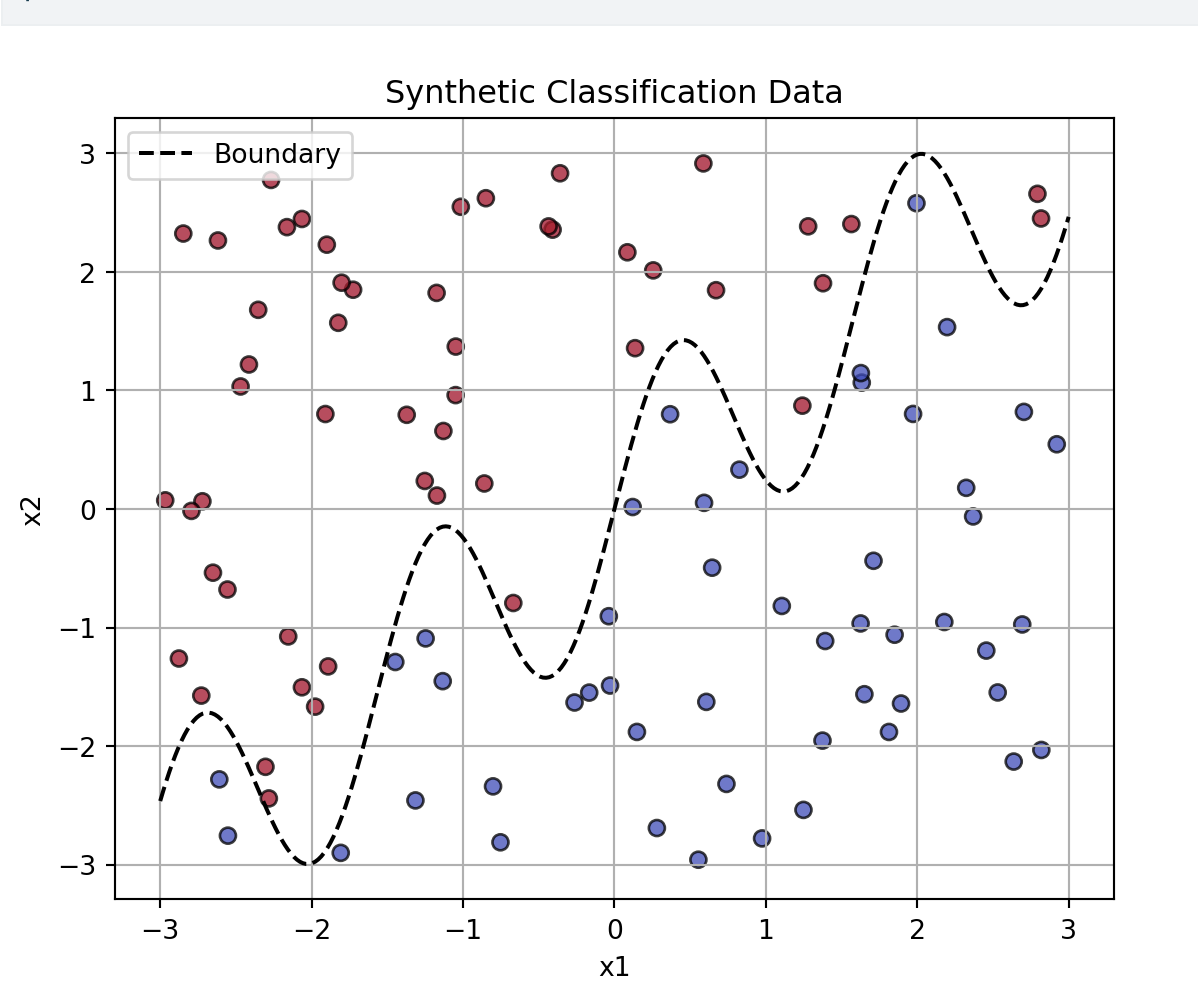





Points satisfying X1 > sin(2 * X2) are labelled as 1 and rest are labelled as 0

The key takeaway: We aren't claiming that real-world labels are generated by a sine function. We deliberately choose this mathematical rule to create a controlled experiment with a nonlinear decision boundary.

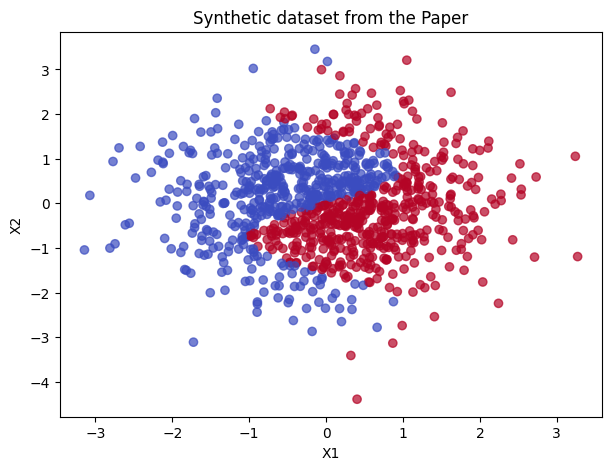

In [20]:
plt.figure(figsize = (7,5))
plt.scatter(X[:,0] , X[: ,1] , c=y, cmap = "coolwarm",alpha = 0.7)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Synthetic dataset from the Paper")
plt.show()

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [38]:
mod = LogisticRegression(max_iter=1000)

In [39]:
mod.fit(X,y)

LogisticRegression(max_iter=1000)

In [40]:
x1_min,x1_max = X[:,0].min() - 0.5 , X[:,0].max() + 0.5
x2_min,x2_max = X[:,1].min() - 0.5 , X[:,1].max() + 0.5

In [41]:
xx1,xx2 = np.meshgrid(
    np.linspace(x1_min,x1_max,300),
    np.linspace(x2_min,x2_max,300)
)

In [42]:
# now predicting probability for every grid point
grid = np.c_[xx1.ravel(),xx2.ravel()]
probs = mod.predict_proba(grid)[:,1].reshape(xx1.shape)

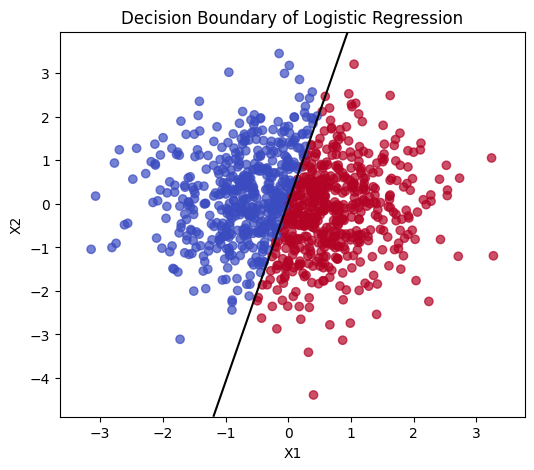

In [43]:
plt.figure(figsize = (6,5))
plt.scatter(
    X[:,0],
    X[:,1],
    c = mod.predict(X),
    cmap = "coolwarm",
    alpha = 0.7
)
plt.contour(xx1,xx2,probs,levels = [0.5],colors = "black")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Decision Boundary of Logistic Regression")
plt.show()

In [44]:
from sklearn.metrics import f1_score,accuracy_score,roc_auc_score
from sklearn.model_selection import train_test_split

In [47]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state=42,stratify = y)

In [49]:
model = LogisticRegression(max_iter=1000)

In [50]:
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [51]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]
# extracting only the probability of class 1


In [53]:
print(f"F1 score  = {f1_score(y_test,y_pred)}")
print(f"Accuracy_score = {accuracy_score(y_test,y_pred)}")
print(f"ROC-AUC score = {roc_auc_score(y_test,y_prob)}")


F1 score  = 0.797979797979798
Accuracy_score = 0.8
ROC-AUC score = 0.8897007306575918


**Now let's add the shift to the data**

In [54]:
shift = 0.5

X_test_shift = X_test.copy()
X_test_shift[:, 0] += shift
#just shifting the X1 column by 0.5


**No fitting of the model again as we are going to check the difference in score if we do covariate shift**

In [55]:
y_shifted_pred = model.predict(X_test_shift)
y_shifted_prob = model.predict_proba(X_test_shift)[:,1]
# extracting only the probability of class 1

In [56]:
print(f"F1 score for the Shifted data = {f1_score(y_test,y_shifted_pred)}")
print(f"Accuracy_score for the Shifted data = {accuracy_score(y_test,y_shifted_pred)}")
print(f"ROC-AUC score for the Shifted data = {roc_auc_score(y_test,y_shifted_prob)}")

F1 score for the Shifted data = 0.8132780082987552
Accuracy_score for the Shifted data = 0.775
ROC-AUC score for the Shifted data = 0.8897007306575918


In [57]:
import pandas as pd

In [59]:
shifts = [0,0.25,0.5,0.75,1.0,1.5,2.0]
results = []
for shift in shifts:
  X_shifted = X_test.copy()
  X_shifted += shift
  y_shifted_pred = model.predict(X_shifted)
  y_shifted_prob = model.predict_proba(X_shifted)[:,1]

  results.append({
      "Shift":shift,
      "F1-score":f1_score(y_test,y_shifted_pred),
      "Accuracy-score" : accuracy_score(y_test,y_shifted_pred),
      "ROC-AUC score" : roc_auc_score(y_test,y_shifted_prob)
  })

results_df = pd.DataFrame(results)
print(results_df)


   Shift  F1-score  Accuracy-score  ROC-AUC score
0   0.00  0.797980           0.800       0.889701
1   0.25  0.796296           0.780       0.889701
2   0.50  0.810345           0.780       0.889701
3   0.75  0.801619           0.755       0.889701
4   1.00  0.778210           0.715       0.889701
5   1.50  0.746377           0.650       0.889701
6   2.00  0.715278           0.590       0.889701


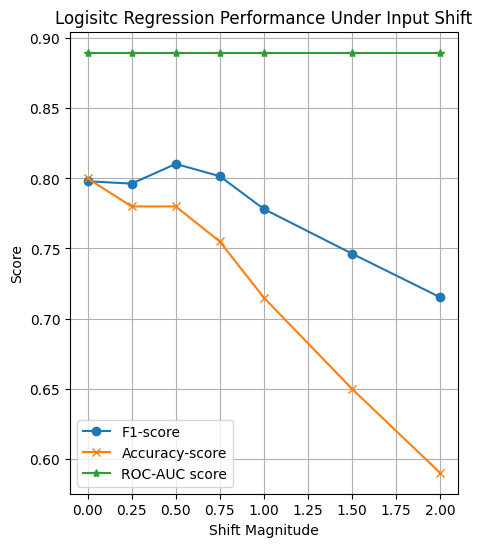

In [62]:
plt.figure(figsize=(5,6))
plt.plot(results_df["Shift"],results_df["F1-score"],label = "F1-score",marker = "o")
plt.plot(results_df["Shift"],results_df["Accuracy-score"],label = "Accuracy-score",marker = "x")
plt.plot(results_df["Shift"],results_df["ROC-AUC score"],label = "ROC-AUC score",marker = "*")
plt.xlabel("Shift Magnitude")
plt.ylabel("Score")
plt.legend()
plt.title("Logisitc Regression Performance Under Input Shift")
plt.grid(True)
plt.show()